## Section 2 – Task 2: day-ahead hourly energy forecast per station

At the end of a day we want the next day's energy use for every station, hour by hour. We first set up the evaluation: a chronological 70/30 split and the naive "average weekday" baseline. We then train two models on lag and calendar features, a linear regression and gradient-boosted trees, and score them on exactly the same test hours as the baseline.

> **Decision notes (internal – remove before hand-in)**
>
> **How to read this notebook.** Normal markdown cells are draft report text. Quote blocks like this one are our own log of decisions, alternatives we rejected and reflections. They are for the group only and should be deleted (or moved to the report where useful) before hand-in, so they do not count towards the word limit.
>
> **What the assignment asks for (Task 2):**
> - Predict energy per station for each of the next 24 hours, made at the end of the previous day.
> - Beat a naive baseline that predicts the historical average for that weekday (we must implement it and compare).
> - No shuffling: first 70% of the data for training, the rest for testing.
> - One model for all stations or one per station is our choice.
>
> **Status:** baseline, features and two untuned models are done. Tuning is still to do (Martin).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.utils.capture import capture_output
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

TARGET = "Energy (kWh)"
LOCAL_TZ = "America/Los_Angeles"
ONE_DAY = pd.Timedelta(days=1)

### 2.1 Station-hour table

Everything below only needs one table with one row per station and hour: `Station Name`, `Hour` (time-zone aware) and `Energy (kWh)`, where an empty value means the station was out of service. The next cell is the only one that knows where that table comes from, so a different cleaning pipeline can be swapped in by replacing it.

For now it comes from `hourly_panel` in `ev_charging_palo_alto.ipynb` (Section 1). That notebook is run once and the result is cached in `station_hours.pkl`; delete the file to rebuild after the cleaning changes.

> **Decision notes (internal – remove before hand-in)**
>
> - **Why Marco's table (`introbid`) and not Dumitrita's:** it already has what forecasting needs. (1) Every station-hour is present, including hours with zero use; a table with only active hours would teach the model that demand is never zero. (2) Energy is spread over the *charging* time, not the whole plugged-in time, so a car that sits fully charged does not add energy to later hours. (3) Long silent gaps at busy stations are marked as outages (empty) instead of zero demand.
> - **The group has not yet agreed on one cleaning pipeline.** That is why the loading cell is isolated. If we switch, only that cell changes; the three `assert` lines check that the new table has the shape the rest of the notebook expects. All numbers below will change slightly.
> - **Why a cache file:** Marco's notebook does not save its tables, and we did not want to edit a teammate's notebook. `station_hours.pkl` (41 MB) is in `.gitignore`. Risk: it goes stale if the cleaning changes, so delete it then.
> - **Outage hours stay empty.** They are left out of the baseline averages, of model training and of scoring. We do not know the true demand in those hours, so counting them as zero would reward a model for predicting outages.
> - **We only forecast energy.** The table also has occupied minutes, which Task 2 does not ask for. It could become an extra feature later.

In [2]:
# --- Swappable cleaning step: must produce `panel` with the three columns below ---
CACHE = Path("station_hours.pkl")
if not CACHE.exists():
    with capture_output():  # hide the cleaning notebook's own prints and plots
        get_ipython().run_line_magic("run", "ev_charging_palo_alto.ipynb")
    hourly_panel.to_pickle(CACHE)

panel = pd.read_pickle(CACHE)[["Station Name", "Hour", TARGET]].copy()

# What the rest of the notebook relies on
assert panel["Hour"].dt.tz is not None, "Hour must be time-zone aware"
assert not panel.duplicated(["Station Name", "Hour"]).any(), "one row per station and hour"
assert (panel[TARGET].dropna() >= 0).all(), "energy cannot be negative"

print("Station-hours:", len(panel), "| stations:", panel["Station Name"].nunique())
print("Out-of-service hours (empty):", panel[TARGET].isna().sum())

Station-hours: 1533155 | stations: 46
Out-of-service hours (empty): 14665


In [3]:
# Days, hours and weekdays follow the local Palo Alto clock, because a forecast "day" is a local day
local_time = panel["Hour"].dt.tz_convert(LOCAL_TZ)
panel["Date"] = local_time.dt.tz_localize(None).dt.normalize()  # the local calendar day, without a time
panel["Hour_Of_Day"] = local_time.dt.hour
panel["Weekday"] = local_time.dt.dayofweek  # 0 = Monday

### 2.2 Chronological 70/30 split

The data is not shuffled. We take the day before which 70% of all in-service station-hours fall, and cut there for every station at once: everything earlier is training data, everything from that day on is the test set. One shared cut-off date means no model ever sees information from the test period, and cutting at midnight keeps the test set made of whole days, which is what a day-ahead forecast predicts.

> **Decision notes (internal – remove before hand-in)**
>
> - **"First 70% of the data" = 70% of the rows, not 70% of the calendar.** The data runs from July 2011 to January 2021, so 70% of the calendar would cut around March 2018. But the network grew, so later years hold more station-hours, and 70% of the rows lands on 23 April 2019. We read "data" as observations. Either reading is defensible; ours gives the model more history.
> - **One cut-off date for all stations, not 70% per station.** With a per-station split, the test period of an old station overlaps the training period of a newer one. A model trained on all stations together would then have seen city-wide events (such as the COVID drop) that lie in another station's "future". A single date rules that out.
> - **Price of that choice:** 13 Sherman stations opened after the cut-off and have no training data. The baseline cannot predict them, so they are not part of the comparison. We report them separately in 2.6.
> - **The test set contains COVID.** It runs April 2019 to January 2021, so almost half of it is after 13 March 2020, when demand collapsed. This matters a lot for the results; see 2.6.
> - **Cut at local midnight** so that every test day is a full day.
> - **No separate validation set yet.** The models below use fixed settings, so nothing was tuned on the test set. Tuning must use a slice from the end of the *training* period.

In [4]:
in_service = panel.dropna(subset=[TARGET])
CUTOFF = in_service["Date"].quantile(0.70).normalize()  # the first test day

train = panel[panel["Date"] < CUTOFF].copy()
test = panel[panel["Date"] >= CUTOFF].copy()

n_train = train[TARGET].notna().sum()
n_test = test[TARGET].notna().sum()
train_share = n_train / (n_train + n_test)

print("Cut-off day (first test day):", CUTOFF.date())
print(f"Train: {train['Date'].min().date()} to {train['Date'].max().date()}, {n_train} station-hours ({train_share:.1%})")
print(f"Test : {test['Date'].min().date()} to {test['Date'].max().date()}, {n_test} station-hours ({1 - train_share:.1%})")

new_stations = sorted(set(test["Station Name"]) - set(train["Station Name"]))
print(f"Stations in test with no training history: {len(new_stations)}")
print(new_stations)

assert train["Date"].max() < CUTOFF <= test["Date"].min()
assert abs(train_share - 0.70) < 0.01

Cut-off day (first test day): 2019-04-23
Train: 2011-07-29 to 2019-04-22, 1062214 station-hours (70.0%)
Test : 2019-04-23 to 2021-01-01, 456276 station-hours (30.0%)
Stations in test with no training history: 13
['PALO ALTO CA / SHERMAN 1', 'PALO ALTO CA / SHERMAN 11', 'PALO ALTO CA / SHERMAN 14', 'PALO ALTO CA / SHERMAN 15', 'PALO ALTO CA / SHERMAN 17', 'PALO ALTO CA / SHERMAN 2', 'PALO ALTO CA / SHERMAN 3', 'PALO ALTO CA / SHERMAN 4', 'PALO ALTO CA / SHERMAN 5', 'PALO ALTO CA / SHERMAN 6', 'PALO ALTO CA / SHERMAN 7', 'PALO ALTO CA / SHERMAN 8', 'PALO ALTO CA / SHERMAN 9']


### 2.3 Baseline: the average weekday

For each station, the baseline predicts an hour with the average energy that station used at that weekday and hour in the training set. So next Monday 9–10 am is predicted as the average of all training Mondays 9–10 am at that station. Out-of-service hours are left out of the averages.

Forecasts are scored with the mean absolute error (MAE) and the root mean squared error (RMSE), both in kWh per station-hour.

> **Decision notes (internal – remove before hand-in)**
>
> - **The baseline is exactly what the assignment describes:** the "average Monday" from the training set, per station. We average over the whole training period. Averaging only the most recent months would be a stronger baseline, but it is not the one we are asked to beat.
> - **Why two metrics:** MAE is the typical miss in kWh and is easy to explain. RMSE punishes large misses more, and large misses are what hurt when planning grid load. A model should win on both.
> - **Why not a percentage error (MAPE):** most station-hours have zero energy, and a percentage of zero is undefined.
> - **`evaluate` is the single scoring function** for the baseline and every model, and `scored` is the single set of test rows (in service, station has training history). Reusing both guarantees a like-for-like comparison.
> - **Observation:** the baseline is a smooth daily hill of about 4 kWh at the busiest station, while real hours jump between 0 and 8–11 kWh. An average cannot predict *which* hours are busy, only that daytime is busier. That is the room the models have to improve.

In [5]:
BASELINE_KEYS = ["Station Name", "Weekday", "Hour_Of_Day"]


def fit_baseline(train):
    """Average energy per station, weekday and hour of day (empty hours are skipped)."""
    return train.groupby(BASELINE_KEYS)[TARGET].mean().rename("Baseline")


def evaluate(actual, predicted):
    """Mean absolute error and root mean squared error, in kWh per station-hour."""
    error = predicted - actual
    return pd.Series({"MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean())})


profile = fit_baseline(train)
test = test.join(profile, on=BASELINE_KEYS)

# The rows every forecast is scored on: station in service, and the station has a training history
scored = test.dropna(subset=[TARGET, "Baseline"]).copy()
print(f"Scored test station-hours: {len(scored)} of {len(test)}")

# Check: the baseline for one station/weekday/hour equals the plain training average
first = scored.iloc[0]
same_slot = (
    (train["Station Name"] == first["Station Name"])
    & (train["Weekday"] == first["Weekday"])
    & (train["Hour_Of_Day"] == first["Hour_Of_Day"])
)
assert np.isclose(first["Baseline"], train.loc[same_slot, TARGET].mean())

# Check: evaluate on a tiny example worked out by hand (errors +1 and -2)
assert np.allclose(evaluate(pd.Series([1.0, 3.0]), pd.Series([2.0, 1.0])), [1.5, np.sqrt(2.5)])

Scored test station-hours: 454108 of 459284


In [6]:
print("Baseline on the test set (kWh per station-hour):")
print(evaluate(scored[TARGET], scored["Baseline"]).round(4).to_string())

Baseline on the test set (kWh per station-hour):
MAE     1.4979
RMSE    2.1501


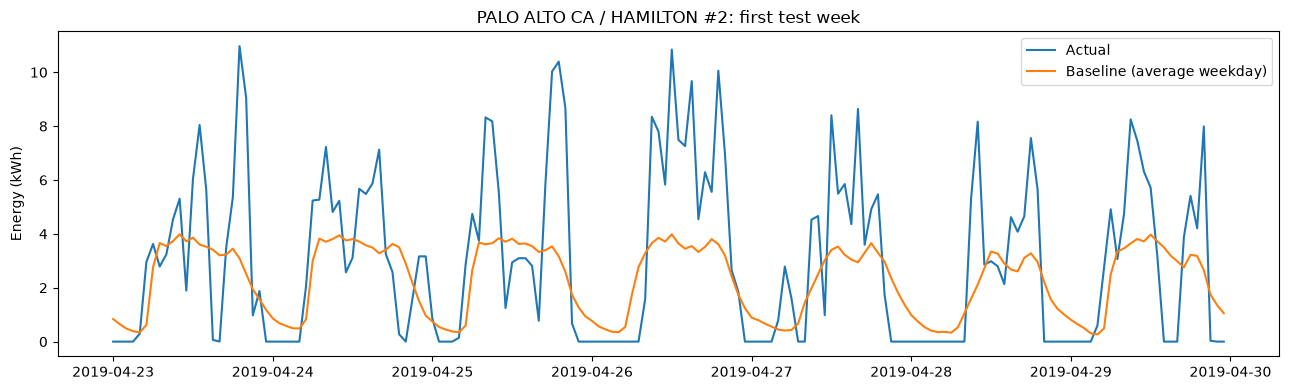

In [7]:
# First test week at the station with the most test energy
busiest_station = scored.groupby("Station Name")[TARGET].sum().idxmax()
first_week = scored[
    (scored["Station Name"] == busiest_station)
    & (scored["Date"] < CUTOFF + 7 * ONE_DAY)
]
week_hours = first_week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(week_hours, first_week[TARGET], label="Actual")
plt.plot(week_hours, first_week["Baseline"], label="Baseline (average weekday)")
plt.title(f"{busiest_station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

### 2.4 Features

The forecast for day *D* is made at midnight, so a feature may only use what is known by the end of day *D-1*. Every lag is therefore counted in whole days back from the target hour: the same clock hour 1, 2, 7 and 14 days ago, the average of that hour over the last 7 days and over the last 4 same weekdays, and the station's average hourly energy yesterday and over the last week. In the test period these lags use actual observations from earlier test days, which is what the company would have at hand each midnight; the models themselves are never refitted.

Calendar features are hour, weekday, month and US federal holidays. The baseline's own prediction and the station are also given to the models, so they start from the average weekday and learn when to move away from it.

> **Decision notes (internal – remove before hand-in)**
>
> - **The rule that prevents leakage:** for hour *h* of day *D*, nothing from day *D* may be used. The shortest lag is therefore "same hour yesterday" (1 day), which is known for all 24 target hours at midnight. A lag of "1 hour ago" would be known only for the first hour of the day, so we do not use hourly lags at all. An `assert` in the code checks the 1-day lag by hand.
> - **Why these lags:** 1 and 2 days capture what the station is doing right now; 7 and 14 days capture the same weekday; the two averages smooth out the noise of single hours (one car more or less changes an hour a lot); the day-level averages tell the model whether the station as a whole is busy or quiet lately.
> - **Using actual test values in the lags is not cheating.** When forecasting day *D* in the test period, days up to *D-1* have really happened. Only the model's *parameters* are frozen at the cut-off.
> - **Why the baseline is a feature:** it summarises years of history for that station, weekday and hour in one number. It is computed from the training set only.
> - **No year or trend feature.** Trees cannot extrapolate beyond the years they have seen, and the lag averages already carry the current level.
> - **Daylight saving:** lags are looked up by local date and clock hour, not by shifting 24 rows. On the two clock-change days an hour is missing or doubled; the doubled hour is averaged and the missing one gives an empty lag.
> - **Empty lags** occur at the start of a station's life and around outages (about 0.1% of test rows). Gradient boosting handles empty values itself; for the linear model they are filled with the column average.
> - **Not used yet, candidates for later:** weather, occupied minutes, school holidays, activity at neighbouring stations.

In [8]:
def energy_same_hour(table, hourly_energy, days_ago):
    """Energy at the same station and clock hour, `days_ago` days before each row (empty if unknown)."""
    wanted = pd.MultiIndex.from_arrays([table["Station Name"], table["Date"] - days_ago * ONE_DAY, table["Hour_Of_Day"]])
    return hourly_energy.reindex(wanted).to_numpy()


def energy_whole_day(table, daily_energy, days_ago):
    """The station's average hourly energy on the day `days_ago` days before each row (empty if unknown)."""
    wanted = pd.MultiIndex.from_arrays([table["Station Name"], table["Date"] - days_ago * ONE_DAY])
    return daily_energy.reindex(wanted).to_numpy()


def build_features(panel, profile):
    table = panel[["Station Name", "Hour", "Date", "Hour_Of_Day", "Weekday", TARGET]].copy()

    # Two lookup tables: energy per station, day and clock hour, and average hourly energy per station and day.
    # Averaging per clock hour also takes care of the hour that occurs twice when the clocks go back.
    hourly_energy = table.groupby(["Station Name", "Date", "Hour_Of_Day"])[TARGET].mean()
    daily_energy = table.groupby(["Station Name", "Date"])[TARGET].mean()

    # The same clock hour on earlier days
    same_hour = pd.DataFrame(index=table.index)
    for days_ago in [1, 2, 3, 4, 5, 6, 7, 14, 21, 28]:
        same_hour[days_ago] = energy_same_hour(table, hourly_energy, days_ago)

    table["Lag_1d"] = same_hour[1]
    table["Lag_2d"] = same_hour[2]
    table["Lag_7d"] = same_hour[7]
    table["Lag_14d"] = same_hour[14]
    table["Hour_Mean_7d"] = same_hour[[1, 2, 3, 4, 5, 6, 7]].mean(axis=1)  # this hour, last 7 days
    table["Hour_Mean_4w"] = same_hour[[7, 14, 21, 28]].mean(axis=1)        # this hour, last 4 same weekdays

    # The station's overall level on earlier days
    whole_day = pd.DataFrame(index=table.index)
    for days_ago in [1, 2, 3, 4, 5, 6, 7]:
        whole_day[days_ago] = energy_whole_day(table, daily_energy, days_ago)

    table["Day_Mean_1d"] = whole_day[1]
    table["Day_Mean_7d"] = whole_day.mean(axis=1)

    # Calendar
    holidays = USFederalHolidayCalendar().holidays(table["Date"].min(), table["Date"].max())
    table["Month"] = table["Date"].dt.month
    table["Is_Holiday"] = table["Date"].isin(holidays).astype(int)

    # The baseline's prediction for this station, weekday and hour (from the training set only)
    table = table.join(profile, on=BASELINE_KEYS)

    table["Station"] = table["Station Name"].astype("category")
    return table


CATEGORY_FEATURES = ["Station", "Hour_Of_Day", "Weekday", "Month"]
NUMBER_FEATURES = ["Is_Holiday", "Baseline", "Lag_1d", "Lag_2d", "Lag_7d", "Lag_14d",
                   "Hour_Mean_7d", "Hour_Mean_4w", "Day_Mean_1d", "Day_Mean_7d"]
FEATURES = CATEGORY_FEATURES + NUMBER_FEATURES

features = build_features(panel, profile)

# Check: no feature looks into the target day. Lag_1d must equal the same station and clock hour one day earlier.
example = features.loc[scored.index[5000]]
day_before = panel[
    (panel["Station Name"] == example["Station Name"])
    & (panel["Date"] == example["Date"] - ONE_DAY)
    & (panel["Hour_Of_Day"] == example["Hour_Of_Day"])
]
assert np.isclose(example["Lag_1d"], day_before[TARGET].mean(), equal_nan=True)

# Check: the baseline feature is the same baseline we score against
assert np.allclose(features.loc[scored.index, "Baseline"], scored["Baseline"])

display(features.loc[scored.index, NUMBER_FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Is_Holiday,454108.0,0.027,0.162,0.0,0.000,0.000,0.000,1.000
Baseline,454108.0,1.632,1.528,0.0,0.284,1.214,2.588,6.548
Lag_1d,454004.0,1.113,2.298,0.0,0.000,0.000,0.489,12.575
Lag_2d,453932.0,1.114,2.299,0.0,0.000,0.000,0.493,12.575
Lag_7d,453572.0,1.123,2.306,0.0,0.000,0.000,0.552,12.575
Lag_14d,453068.0,1.132,2.314,0.0,0.000,0.000,0.611,12.720
Hour_Mean_7d,454036.0,1.117,1.564,0.0,0.000,0.393,1.734,9.388
Hour_Mean_4w,453611.0,1.135,1.754,0.0,0.000,0.000,1.641,12.102
Day_Mean_1d,454082.0,1.113,1.122,0.0,0.082,0.836,1.762,7.128
Day_Mean_7d,454082.0,1.117,0.906,0.0,0.364,0.965,1.692,4.604


### 2.5 Models

Both models are trained once on the training set, for all stations together, on the same features.

- **Linear regression** is the simple reference: the forecast is a weighted sum of the lags and the baseline, plus a fixed shift per station, hour, weekday and month.
- **Gradient-boosted trees** can also learn interactions, for example that yesterday's demand matters more on weekdays than on weekends, or differently at different stations.

Both are fitted with squared error, so they predict the expected energy just like the baseline does. Settings are fixed in advance and were not tuned on the test set. Predictions below zero are set to zero.

> **Decision notes (internal – remove before hand-in)**
>
> - **Why two models:** the grading asks whether we used one or several models and linear or non-linear ones. The linear model also answers a useful question: how much of the gain comes from simply having lag features, and how much from a more flexible model?
> - **One model for all stations, not one per station.** Stations share the same daily and weekly rhythm, so a shared model has far more data to learn it from. Quiet stations have too little data for their own model. And a shared model can forecast a station it has never seen, which per-station models cannot. Station differences are still captured through the `Station` feature and the per-station baseline.
> - **Why gradient boosting among the non-linear options:** it works well on mixed table data like ours, trains in seconds on a million rows, accepts empty lags and a category column directly, and needs no scaling. `HistGradientBoostingRegressor` is in scikit-learn, so no extra package.
> - **Linear model details:** station, hour, weekday and month are one-hot encoded (a separate shift for each value), because "hour 23" is not 23 times "hour 1". Empty lags are filled with the column average. Plain least squares, no regularisation, so there is nothing to tune.
> - **Squared-error loss on purpose.** Most hours are zero. A model trained on absolute error would learn to predict close to zero almost everywhere: good MAE, useless for the grid. Squared error targets the average, which is also what the baseline predicts.
> - **Boosting settings are untuned:** learning rate 0.05, 300 trees, scikit-learn defaults otherwise. **To do (Martin): tuning.** Use the last part of the training period as validation, never the test set.
> - **Clipping at zero:** energy cannot be negative, and both models sometimes predict slightly below zero for quiet hours.

In [9]:
is_train = (features["Date"] < CUTOFF) & features[TARGET].notna()

X_train = features.loc[is_train, FEATURES]
y_train = features.loc[is_train, TARGET]
X_test = features.loc[scored.index, FEATURES]  # the same test rows as the baseline

# Model 1: linear regression
linear_model = make_pipeline(
    ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORY_FEATURES),
        ("numbers", SimpleImputer(strategy="mean"), NUMBER_FEATURES),
    ]),
    LinearRegression(),
)
linear_model.fit(X_train, y_train)

# Model 2: gradient-boosted trees (uses the Station category and empty lags as they are)
boosting_model = HistGradientBoostingRegressor(
    categorical_features=["Station"],
    learning_rate=0.05,
    max_iter=300,
    random_state=0,
)
boosting_model.fit(X_train, y_train)

scored["Linear"] = linear_model.predict(X_test).clip(min=0)
scored["Boosting"] = boosting_model.predict(X_test).clip(min=0)

print(f"Trained on {len(X_train)} station-hours, predicted {len(X_test)}")

Trained on 1062214 station-hours, predicted 454108


### 2.6 Results

In [10]:
FORECASTS = ["Baseline", "Linear", "Boosting"]


def score_forecasts(rows):
    """MAE and RMSE of every forecast on the given rows: one line per forecast."""
    return pd.DataFrame({name: evaluate(rows[TARGET], rows[name]) for name in FORECASTS}).T


results = score_forecasts(scored)
results["MAE vs baseline"] = results["MAE"] / results.loc["Baseline", "MAE"] - 1
results["RMSE vs baseline"] = results["RMSE"] / results.loc["Baseline", "RMSE"] - 1

print(f"Test set, {len(scored)} station-hours (kWh per station-hour):")
print(results.to_string(formatters={
    "MAE": "{:.4f}".format, "RMSE": "{:.4f}".format,
    "MAE vs baseline": "{:+.1%}".format, "RMSE vs baseline": "{:+.1%}".format,
}))

Test set, 454108 station-hours (kWh per station-hour):
            MAE   RMSE MAE vs baseline RMSE vs baseline
Baseline 1.4979 2.1501           +0.0%            +0.0%
Linear   1.1560 1.8311          -22.8%           -14.8%
Boosting 1.1238 1.8153          -25.0%           -15.6%


In [11]:
# Before and after the COVID drop in demand
COVID_START = pd.Timestamp("2020-03-13")
before_covid = scored[scored["Date"] < COVID_START]
during_covid = scored[scored["Date"] >= COVID_START]

print(f"Before 13 March 2020 ({len(before_covid)} station-hours, mean energy {before_covid[TARGET].mean():.3f} kWh):")
print(score_forecasts(before_covid).round(3).to_string())
print(f"\nFrom 13 March 2020 ({len(during_covid)} station-hours, mean energy {during_covid[TARGET].mean():.3f} kWh):")
print(score_forecasts(during_covid).round(3).to_string())

Before 13 March 2020 (255151 station-hours, mean energy 1.586 kWh):
            MAE   RMSE
Baseline  1.454  2.139
Linear    1.365  2.044
Boosting  1.315  2.028

From 13 March 2020 (198957 station-hours, mean energy 0.504 kWh):
            MAE   RMSE
Baseline  1.555  2.164
Linear    0.888  1.516
Boosting  0.878  1.498


In [12]:
# Per station: do the models win everywhere, or only on average?
mae_by_station = scored.groupby("Station Name")[[TARGET] + FORECASTS].apply(lambda rows: score_forecasts(rows)["MAE"])
rmse_by_station = scored.groupby("Station Name")[[TARGET] + FORECASTS].apply(lambda rows: score_forecasts(rows)["RMSE"])

for name in ["Linear", "Boosting"]:
    lower_mae = (mae_by_station[name] < mae_by_station["Baseline"]).sum()
    lower_rmse = (rmse_by_station[name] < rmse_by_station["Baseline"]).sum()
    print(f"{name}: lower MAE than the baseline at {lower_mae} of {len(mae_by_station)} stations, lower RMSE at {lower_rmse}")

print("\nMAE per station (kWh per station-hour):")
display(mae_by_station.sort_values("Baseline", ascending=False).round(3))

Linear: lower MAE than the baseline at 33 of 33 stations, lower RMSE at 33
Boosting: lower MAE than the baseline at 33 of 33 stations, lower RMSE at 33

MAE per station (kWh per station-hour):


MAE,Baseline,Linear,Boosting
Station Name,,,
PALO ALTO CA / WEBSTER #2,2.358,1.559,1.557
PALO ALTO CA / WEBSTER #1,2.336,1.811,1.843
PALO ALTO CA / HAMILTON #2,2.133,1.865,1.749
PALO ALTO CA / WEBSTER #3,2.123,1.410,1.384
PALO ALTO CA / HIGH #1,2.086,1.346,1.245
PALO ALTO CA / HIGH #3,1.997,1.585,1.590
PALO ALTO CA / TED THOMPSON #1,1.989,1.558,1.551
PALO ALTO CA / HIGH #2,1.833,1.344,1.334
PALO ALTO CA / CAMBRIDGE #1,1.803,1.429,1.398


In [13]:
# The stations that opened after the cut-off. The baseline has no history for them,
# so they are not part of the comparison above, but the models can still forecast them from their lags.
new_rows = features[
    features["Station Name"].isin(new_stations)
    & (features["Date"] >= CUTOFF)
    & features[TARGET].notna()
]
new_linear = pd.Series(linear_model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
new_boosting = pd.Series(boosting_model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
always_zero = pd.Series(0.0, index=new_rows.index)

print(f"New stations: {len(new_rows)} station-hours, mean energy {new_rows[TARGET].mean():.3f} kWh")
print(pd.DataFrame({
    "Always zero": evaluate(new_rows[TARGET], always_zero),
    "Linear": evaluate(new_rows[TARGET], new_linear),
    "Boosting": evaluate(new_rows[TARGET], new_boosting),
}).T.round(3).to_string())

New stations: 2168 station-hours, mean energy 0.240 kWh
               MAE   RMSE
Always zero  0.240  1.093
Linear       0.727  1.165
Boosting     0.310  1.091


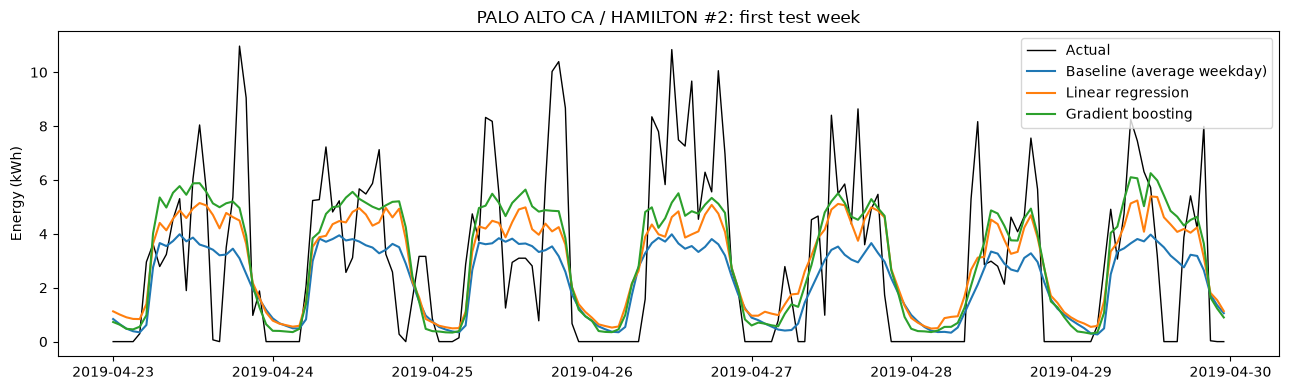

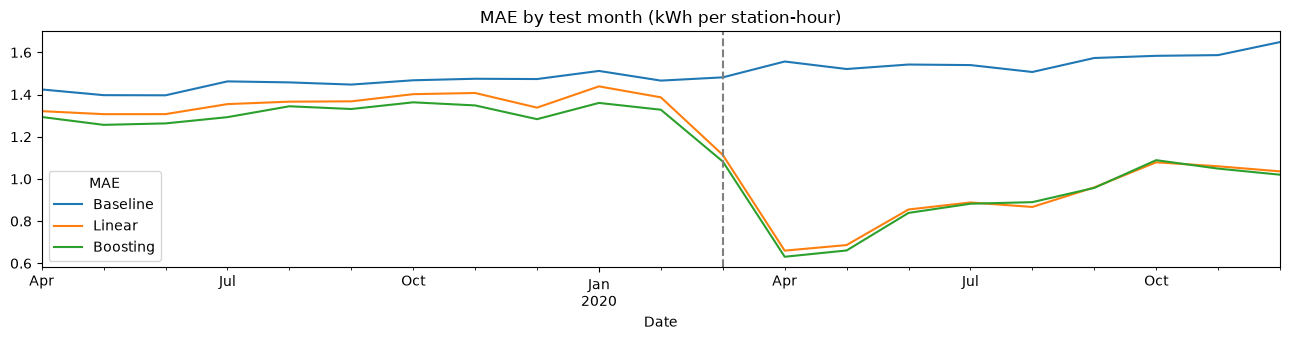

In [14]:
# Same station and week as in 2.3, now with the models
first_week = scored[
    (scored["Station Name"] == busiest_station)
    & (scored["Date"] < CUTOFF + 7 * ONE_DAY)
]
week_hours = first_week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(week_hours, first_week[TARGET], label="Actual", color="black", linewidth=1)
plt.plot(week_hours, first_week["Baseline"], label="Baseline (average weekday)")
plt.plot(week_hours, first_week["Linear"], label="Linear regression")
plt.plot(week_hours, first_week["Boosting"], label="Gradient boosting")
plt.title(f"{busiest_station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

# Error per month of the test period (the last month is a single day, so it is left out)
mae_by_month = scored.groupby(scored["Date"].dt.to_period("M"))[[TARGET] + FORECASTS].apply(
    lambda rows: score_forecasts(rows)["MAE"]
)
mae_by_month.iloc[:-1].plot(figsize=(13, 3.5), title="MAE by test month (kWh per station-hour)")
plt.axvline(pd.Period("2020-03", "M"), color="grey", linestyle="--")
plt.tight_layout()
plt.show()

> **Decision notes (internal – remove before hand-in)**
>
> **Reflections on the results (numbers from the run with Marco's cleaning, untuned models)**
>
> - **Both models beat the baseline on both metrics, at all 33 scored stations.** Baseline MAE 1.498 / RMSE 2.150. Linear 1.156 / 1.831 (−22.8% / −14.8%). Boosting 1.124 / 1.815 (−25.0% / −15.6%). The requirement of the assignment is met.
> - **Most of the gain is COVID, and we should say so in the report.** From 13 March 2020 demand fell to about a third (mean 0.50 kWh per station-hour, against 1.59 before). The baseline keeps predicting pre-pandemic levels; the lags let the models follow the drop within days. In that period boosting cuts MAE by 44% (1.555 to 0.878). Before COVID the gain is much smaller: MAE −9.6% (1.454 to 1.315) and RMSE −5.2% (2.139 to 2.028). The honest summary is "about 10% better in normal times, and far more robust when demand shifts".
> - **Features matter more than the model type.** The linear model already gets most of the improvement; boosting adds about 2 percentage points on MAE overall and is better at 29 of 33 stations. Before COVID the gap is a little larger (MAE 1.315 against 1.365). So further gains are more likely to come from new information (weather, occupancy, neighbouring stations) than from a fancier model. Tuning may still help boosting a little.
> - **Why the errors stay high:** before COVID the MAE (1.3) is almost as large as the mean energy (1.6). Energy in a single station-hour depends on whether one or two cars happen to plug in, which is close to random at day-ahead horizon. In the weekly plot the models predict a smooth daytime hill, while reality jumps between 0 and 8–11 kWh. The models get the *level* right (they sit above the baseline in the first test week, because the station had become busier than its long-run average), not the individual spikes. Aggregated over stations or hours the forecasts would look much better; that could be worth showing.
> - **New stations: no real skill.** On the 13 Sherman stations boosting scores MAE 0.310 / RMSE 1.091, but simply predicting zero scores 0.240 / 1.093, because these stations were barely used (mean 0.24 kWh). The linear model is clearly worse (MAE 0.727): with no baseline value for these stations it falls back on the average baseline of all stations. We should not claim that the model handles new stations well, only that it can produce a forecast for them.
> - **The largest relative gains are at the three quietest stations** (MPL #1–#3, around −65% MAE), where the baseline still predicts activity that has stopped. The smallest gain is Ted Thompson #3 (−8%).
>
> **Open points**
> - Tuning of the boosting model with a validation slice from the end of the training period (Martin).
> - Decide with the group whether to report results with and without the COVID period, or to discuss COVID only in the text.
> - Re-run everything once the group has settled on one cleaning pipeline.
> - Possible extras if time allows: a feature-importance plot, and error by hour of day.